Karen Mayerli Tahuite Ortiz  
carnet: 202103058    
  
Burden (10e)  
Ejercicios 5.3  
Versión de python 3.12.0

**10.** Dado el problema de valor inicial $y' = \frac{1}{t^2} - \frac{y}{t} - y^2, \qquad 1 \leq t \leq 2, \qquad y(1) = -1,$ con solución exacta $y(t) = -1/t$:
  
**a.** Use el método de Taylor de orden 2 con $h = 0.05$ para aproximar la solución $y$ y compárela con los valores reales de $y$.

**b.** Use las respuestas generadas en la parte a) y la interpolación lineal para aproximar $y$ en los siguientes valores, y compárelos con los valores reales de $y$.

$$
\text{i. } y(1.052)
\qquad\qquad\qquad
\text{ii. } y(1.555)
\qquad\qquad\qquad
\text{iii. } y(1.978)
$$


**c.** Utilice el método de Taylor de orden 4 con $h = 0.05$ para aproximar la solución $y$ y compárela con los valores reales de $y$.

**d.** Use las respuestas generadas en la parte c) y la interpolación cúbica por tramos de Hermite para aproximar $y$ en los siguientes valores, y compárelos con los valores reales de $y$.
  
$$
\text{i. } y(1.052)
\qquad\qquad\qquad
\text{ii. } y(1.555)
\qquad\qquad\qquad
\text{iii. } y(1.978)
$$

In [15]:
# Librerias 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
# Parámetros
a = 1
b = 2
h = 0.05
y0 = -1

# Solución exacta
def y_exacta(t):
    return -1/t

# Función f(t,y)
def f(t, y):
    return 1/t**2 - y/t - y**2

In [17]:
# Implementación de el método de Taylor de orden 2

# Número de pasos
N = int((b - a) / h)

# Vectores
t = np.zeros(N + 1)
w = np.zeros(N + 1)

# Condición inicial
t[0] = a
w[0] = y0

# Derivadas parciales de f
def f_t(t, y):
    return -2/t**3 + y/t**2

def f_y(t, y):
    return -1/t - 2*y

# Método de Taylor de orden 2
for i in range(N):
    t[i+1] = t[i] + h # Actualizar el tiempo
    
    # Calcular la segunda derivada
    # y'' = f_t + f_y*f
    segunda_derivada = f_t(t[i], w[i]) + f_y(t[i], w[i]) * f(t[i], w[i]) 
    
    w[i+1] = (w[i] + h*f(t[i], w[i]) + (h**2/2)*segunda_derivada) # Actualización de la aproximación 


In [18]:
# Inciso a.
# Solución exacta
y = y_exacta(t)

# Error absoluto
error = np.abs(y - w)

# Tabla de resultados
tabla = pd.DataFrame({
    "i": np.arange(N + 1),
    "t_i": t,
    "w_i": w,
    "y(t_i)": y,
    "Error absoluto": error})

display(tabla)

,i,t_i,w_i,y(t_i),Error absoluto
0,0,1.0000000000,-1.0000000000,-1.0000000000,0.0000000000
1,1,1.0500000000,-0.9525000000,-0.9523809524,0.0001190476
2,2,1.1000000000,-0.9093137898,-0.9090909091,0.0002228807
3,3,1.1500000000,-0.8698798963,-0.8695652174,0.0003146789
4,4,1.2000000000,-0.8337301905,-0.8333333333,0.0003968572
5,5,1.2500000000,-0.8004712716,-0.8000000000,0.0004712716
6,6,1.3000000000,-0.7697701343,-0.7692307692,0.0005393650
7,7,1.3500000000,-0.7413430110,-0.7407407407,0.0006022702
8,8,1.4000000000,-0.7149465994,-0.7142857143,0.0006608851
9,9,1.4500000000,-0.6903711001,-0.6896551724,0.0007159277


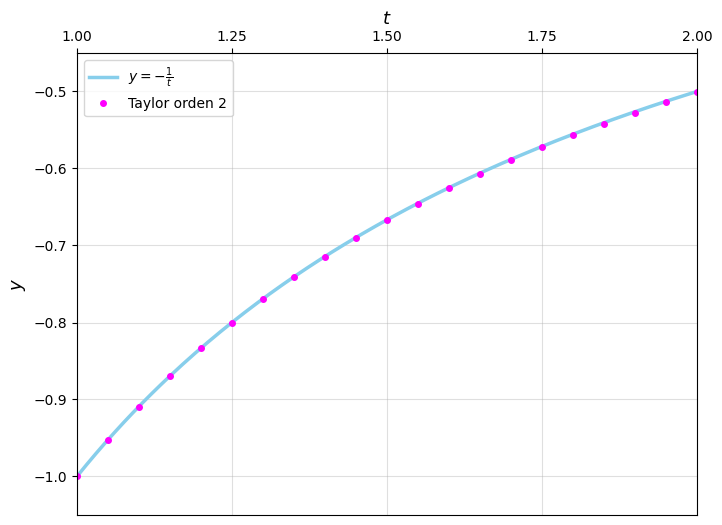

In [19]:
# Gráfica comparativa del método de Taylor de orden 2 y la solución exacta

t_exacta = np.linspace(1, 2, 200)
y_exacta_grafica = -1/t_exacta

fig, ax = plt.subplots(figsize=(8, 6))

# Solución exacta
ax.plot(t_exacta, y_exacta_grafica,
        color="#87CEEB", linewidth=2.5,
        label=r"$y=-\frac{1}{t}$")

# Puntos del método de Taylor de orden 2
ax.plot(tabla["t_i"], tabla["w_i"], "o",
        color="magenta", markersize=4,
        label="Taylor orden 2")

# Límites
ax.set_xlim(1, 2)
ax.set_ylim(-1.05, -0.45)

# Marcas de los ejes
ax.set_xticks([1, 1.25, 1.5, 1.75, 2])
ax.set_yticks([-1, -0.9, -0.8, -0.7, -0.6, -0.5])

# Configuarción del eje t
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

# Etiquetas
ax.set_xlabel("$t$", fontsize=13)
ax.set_ylabel("$y$", fontsize=13)

# Cuadrícula
ax.grid(True, alpha=0.4)

ax.legend()

plt.show()

In [20]:
# Inciso b: Interpolación lineal

# Valores donde se desea aproximar la solución
puntos = np.array([1.052, 1.555, 1.978])

# Interpolación lineal
aproximaciones = np.interp(puntos, t, w)

# Valores exactos
valores_exactos = y_exacta(puntos)

# Error absoluto
errores = np.abs(valores_exactos - aproximaciones)

# Tabla comparativa
tabla_b = pd.DataFrame({
    "t": puntos,
    "Interpolación lineal": aproximaciones,
    "Solución exacta": valores_exactos,
    "Error absoluto": errores})

display(tabla_b)

,t,Interpolación lineal,Solución exacta,Error absoluto
0,1.0520000000,-0.9507725516,-0.9505703422,0.0002022094
1,1.5550000000,-0.6439674014,-0.6430868167,0.0008805847
2,1.9780000000,-0.5068199724,-0.5055611729,0.0012587995


In [21]:
# Inciso c: Método de Taylor de orden 4

# Número de pasos
N = int((b - a) / h)

# Vectores
t4 = np.zeros(N + 1)
w4 = np.zeros(N + 1)

# Condición inicial
t4[0] = a
w4[0] = y0

# Derivadas de f para obtener y'', y''' y y''''
def f_t(t, y):
    return -2/t**3 + y/t**2

def f_y(t, y):
    return -1/t - 2*y

# Derivada segunda
def y2(t, y):
    return f_t(t, y) + f_y(t, y)*f(t, y)

# Derivada tercera
def y3(t, y):
    return (6/t**4 - 2*y/t**3
            + (-2/t**2)*f(t, y)
            + f_y(t, y)*y2(t, y))

# Derivada cuarta
def y4(t, y):
    return (-24/t**5 + 6*y/t**4
            + 4/t**3*f(t, y)
            - 2/t**2*y2(t, y)
            + (-2/t**2)*y2(t, y)
            + f_y(t, y)*y3(t, y))

# Método de Taylor de orden 4
for i in range(N):
    t4[i+1] = t4[i] + h
    
    w4[i+1] = (w4[i] + h*f(t4[i], w4[i]) + (h**2/2)*y2(t4[i], w4[i]) + (h**3/6)*y3(t4[i], w4[i]) + (h**4/24)*y4(t4[i], w4[i]))

# Solución exacta
y4_exacta = y_exacta(t4)

# Error absoluto
error4 = np.abs(y4_exacta - w4)

# Tabla de resultados
tabla_c = pd.DataFrame({
    "i": np.arange(N + 1),
    "t_i": t4,
    "w_i": w4,
    "y(t_i)": y4_exacta,
    "Error absoluto": error4})

display(tabla_c)

,i,t_i,w_i,y(t_i),Error absoluto
0,0,1.0000000000,-1.0000000000,-1.0000000000,0.0000000000
1,1,1.0500000000,-0.9524203125,-0.9523809524,0.0000393601
2,2,1.1000000000,-0.9091646050,-0.9090909091,0.0000736959
3,3,1.1500000000,-0.8696692741,-0.8695652174,0.0001040567
4,4,1.2000000000,-0.8334645727,-0.8333333333,0.0001312393
5,5,1.2500000000,-0.8001558564,-0.8000000000,0.0001558564
6,6,1.3000000000,-0.7694091533,-0.7692307692,0.0001783840
7,7,1.3500000000,-0.7409399370,-0.7407407407,0.0001991963
8,8,1.4000000000,-0.7145043039,-0.7142857143,0.0002185896
9,9,1.4500000000,-0.6898919734,-0.6896551724,0.0002368010


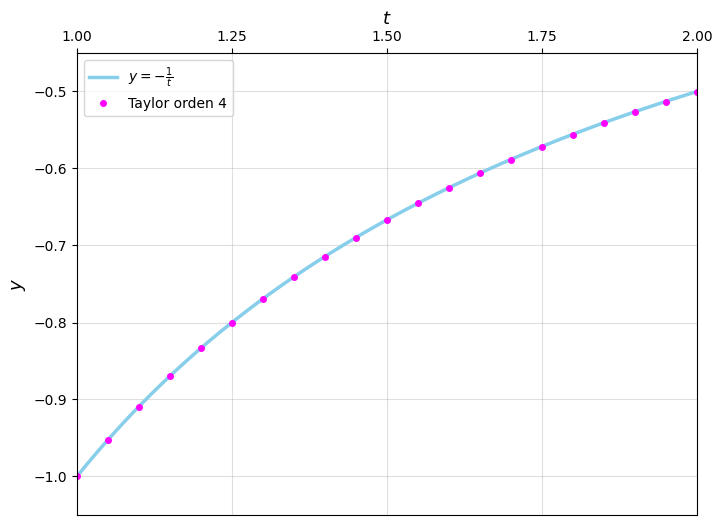

In [22]:
# Gráfica comparativa del método de Taylor de orden 4 y la solución exacta

t_exacta = np.linspace(1, 2, 200)
y_exacta_grafica = -1/t_exacta

fig, ax = plt.subplots(figsize=(8, 6))

# Solución exacta
ax.plot(t_exacta, y_exacta_grafica,
        color="#87CEEB", linewidth=2.5,
        label=r"$y=-\frac{1}{t}$")

# Puntos del método de Taylor de orden 4
ax.plot(tabla_c["t_i"], tabla_c["w_i"], "o",
        color="magenta", markersize=4,
        label="Taylor orden 4")

# Límites
ax.set_xlim(1, 2)
ax.set_ylim(-1.05, -0.45)

# Marcas de los ejes
ax.set_xticks([1, 1.25, 1.5, 1.75, 2])
ax.set_yticks([-1, -0.9, -0.8, -0.7, -0.6, -0.5])

# Eje t
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

# Etiquetas
ax.set_xlabel("$t$", fontsize=13)
ax.set_ylabel("$y$", fontsize=13)

# Cuadrícula
ax.grid(True, alpha=0.4)

ax.legend()

plt.show()

In [23]:
# Inciso d: Interpolación cúbica por tramos de Hermite

# Puntos donde se desea aproximar la solución
puntos = np.array([1.052, 1.555, 1.978])

# Valores de Taylor de orden 4
x = t4
w = w4

# Derivadas aproximadas en los puntos de Taylor
derivadas = f(x, w)

# Función de interpolación cúbica de Hermite
def hermite_cubica(x0, x1, y0, y1, dy0, dy1, x):
    
    h_local = x1 - x0
    s = (x - x0) / h_local

    H00 = 2*s**3 - 3*s**2 + 1
    H10 = s**3 - 2*s**2 + s
    H01 = -2*s**3 + 3*s**2
    H11 = s**3 - s**2

    return (H00*y0
            + H10*h_local*dy0
            + H01*y1
            + H11*h_local*dy1)

# Interpolación para cada punto
aproximaciones = []

for p in puntos:
    
    # Encontrar el intervalo [x_i, x_{i+1}]
    i = np.searchsorted(x, p) - 1
    
    # Interpolación de Hermite
    valor = hermite_cubica(
        x[i], x[i+1],
        w[i], w[i+1],
        derivadas[i], derivadas[i+1],
        p
    )
    
    aproximaciones.append(valor)

aproximaciones = np.array(aproximaciones)

# Valores exactos
valores_exactos = y_exacta(puntos)

# Error absoluto
errores = np.abs(valores_exactos - aproximaciones)

# Tabla comparativa
tabla_d = pd.DataFrame({
    "t": puntos,
    "Hermite cúbico": aproximaciones,
    "Solución exacta": valores_exactos,
    "Error absoluto": errores })

display(tabla_d)

,t,Hermite cúbico,Solución exacta,Error absoluto
0,1.0520000000,-0.9506099201,-0.9505703422,0.0000395779
1,1.5550000000,-0.6433582830,-0.6430868167,0.0002714663
2,1.9780000000,-0.5059511716,-0.5055611729,0.0003899987


Al comparar los errores absolutos obtenidos para cada método, se concluye que el método de Taylor de orden 4 presenta menor error que el método de Taylor de orden 2; debido a que considera términos de mayor orden en la expansión de Taylor, logrando una aproximación más precisa de la solución. Asimismo, la interpolación cúbica por tramos de Hermite presenta menor error que la interpolación lineal, ya que no solo utiliza los valores de la función sino que también incorpora información sobre sus derivadas, proporcionando una aproximación más precisa.